# **MÓDULO 13**
# Projeto - Fundamentos da Descoberta de Dados

Nesse projeto trabalharemos com a base de dados de produtos de um supermercado do Chile.
A ideia é que vocês apliquem os conceitos estatísticos vistos no último módulo, mais os conceitos de visualizações de dados através de gráficos e finalizem publicando no seu github!

In [8]:
import pandas as pd
import matplotlib.pyplot as plt
import plotly.express as px

Faça a leitura dos dados do arquivo CSV:


Altere o código abaixo de acordo com seu diretório.

#### corrigi usando "," pois com ";" não ficou adequado para visualização

In [12]:
df = pd.read_csv("MODULO7_PROJETOFINAL_BASE_SUPERMERCADO.csv", delimiter=',')

df.head(10)

,title,Marca,Preco_Normal,Preco_Desconto,Preco_Anterior,Desconto,Categoria
0,"Pack 12 un, Leche extra proteína 1 L",Loncoleche,19788,0,0,0,lacteos
1,"Pack 12 un, Leche chocolate receta original 1 L",Soprole,18228,0,0,0,lacteos
2,"Pack 12 un, Leche semidescremada chocolate 1 L",Soprole,18228,0,0,0,lacteos
3,"Pack 12 un, Leche semidescremada frutilla 1 L",Soprole,18228,0,0,0,lacteos
4,"Pack 12 un, Leche sin lactosa chocolate 1 L",Loncoleche,17988,0,0,0,lacteos
5,"Pack 12 un, Leche sin lactosa frutilla 1 L",Loncoleche,17988,0,0,0,lacteos
6,"Pack 12 un, Leche saborizada light chocolate 1 L",Loncoleche,17988,0,0,0,lacteos
7,"Pack 12 un, Leche saborizada frutilla 1 L",Colun,17388,0,0,0,lacteos
8,"Pack 12 un, Leche saborizada vainilla 1 L",Colun,17388,0,0,0,lacteos
9,"Pack 12 un, Leche saborizada manjar 1 L",Colun,17388,0,0,0,lacteos


Os campos do nosso dataframe são:

**Title:** Nome do produto.


**Marca:** A marca do produto.


**Preco_Normal:** O preço em que o produto costuma ser vendido quando não há desconto.


**Preco_Desconto:** O preço vendido após o desconto ser aplicado.


**Preco_Anterior:** Preço em que era comercializado o produto antes do desconto aplicado.


**Desconto:** Total de desconto aplicado.






As colunas que aparecem com valores 0 são para os produtos onde não tivemos descontos aplicados.


As categorias estão em espanhol!

# 1 - Traga a média e a mediana dos preços - coluna Preco_Normal - por categoria de produto.
# Identifique as categorias que parecem ter um valor de média abaixo ou acima da mediana.

In [13]:
#Seu código aqui para a média
df.groupby('Categoria')['Preco_Normal'].agg(media= 'mean', mediana= 'median')

,media,mediana
Categoria,,
belleza-y-cuidado-personal,1783.556485,1569.0
comidas-preparadas,3095.043478,3290.0
congelados,2108.042553,1519.0
frutas,1724.473684,1195.0
instantaneos-y-sopas,765.491228,439.0
lacteos,2385.219239,989.0
verduras,1343.296875,1180.0


In [15]:
#Seu código aqui para a mediana
df.groupby('Categoria')['Preco_Normal'].agg(mediana = 'median')

,mediana
Categoria,
belleza-y-cuidado-personal,1569.0
comidas-preparadas,3290.0
congelados,1519.0
frutas,1195.0
instantaneos-y-sopas,439.0
lacteos,989.0
verduras,1180.0


Digite aqui as categorias:

# 2 - Traga o desvio padrão por categoria de produto.
# Qual o comportamento da média e mediana nas categorias com maior desvio?

In [22]:
#Seu código aqui
df.groupby('Categoria')['Preco_Normal'].agg(
    Media='mean',
    Mediana= 'median',
    Desvio_Padrão='std'

).reset_index().sort_values(by='Desvio_Padrão',ascending=False)

,Categoria,Media,Mediana,Desvio_Padrão
5,lacteos,2385.219239,989.0,3925.816164
0,belleza-y-cuidado-personal,1783.556485,1569.0,2210.041719
2,congelados,2108.042553,1519.0,2111.539896
1,comidas-preparadas,3095.043478,3290.0,2019.911428
3,frutas,1724.473684,1195.0,1639.151114
4,instantaneos-y-sopas,765.491228,439.0,1170.232869
6,verduras,1343.296875,1180.0,1012.699625


As categorias com maior desvio padrão são Lácteos, Beleza e Cuidados Pessoais, Congelados e Comidas Preparadas, indicando uma maior dispersão nos preços dos produtos dessas categorias.

Observa-se que, nas categorias Lácteos e Congelados, a média é superior à mediana, sugerindo a presença de produtos com preços mais elevados que podem influenciar a média. Em Beleza e Cuidados Pessoais, a média e a mediana apresentam valores relativamente próximos. Já em Comidas Preparadas, a mediana é superior à média.

Portanto, as diferenças entre média e mediana demonstram que as categorias apresentam comportamentos distintos na distribuição dos preços, enquanto os elevados desvios padrão indicam uma grande variabilidade nos valores dos produtos.

# 3 - Plot um boxplot da distribuição do Preco_Normal para a categoria que você identificou que tem o maior desvio padrão. Como é a distribuição desses dados segundo o boxplot? Você identifica muitos outliers?

Dica: Para trazer apenas os dados da categoria que você deseja você pode usar o df.loc[df['Categoria'] == 'CATEGORIA ESCOLHIDA'

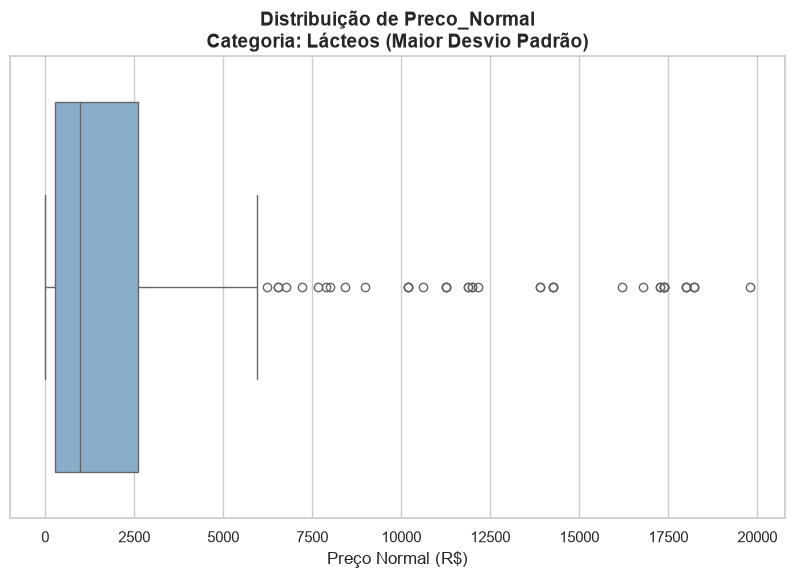

In [23]:
#Seu código aqui
import matplotlib.pyplot as plt
import seaborn as sns

# Configura o estilo visual do seaborn para gráficos mais limpos
sns.set_theme(style="whitegrid")

# Seleciona somente as linhas da categoria 'lacteos'
df_lacteos = df.loc[df['Categoria'] == 'lacteos']


plt.figure(figsize=(10, 6))  # Define o tamanho da imagem (largura, altura)


# 'x' define a variável numérica, color= define a cor principal
ax = sns.boxplot(x=df_lacteos['Preco_Normal'], color='#7eb0d5')


plt.title('Distribuição de Preco_Normal\nCategoria: Lácteos (Maior Desvio Padrão)', fontsize=14, fontweight='bold')
plt.xlabel('Preço Normal (R$)', fontsize=12)

#Removi labels do eixo Y para um gráfico mais bonito
ax.set_yticklabels([])

#visualização
plt.show()

O boxplot da categoria Lácteos mostra uma distribuição assimétrica à direita, indicando que a maior parte dos produtos possui preços mais baixos, enquanto alguns produtos apresentam preços significativamente superiores. Também é possível observar uma grande quantidade de outliers acima do limite superior do boxplot. Esses valores extremos aumentam a dispersão dos dados e ajudam a explicar o elevado desvio padrão encontrado para essa categoria.

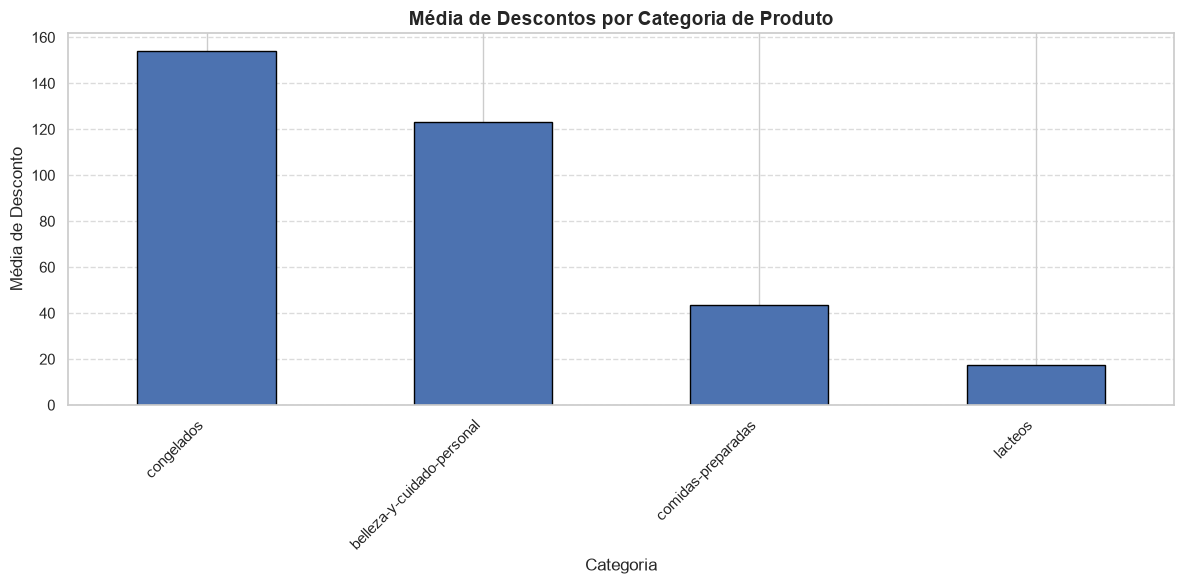

In [26]:
# Seu código aqui
import matplotlib.pyplot as plt
import seaborn as sns

# Configurar o estilo visual
sns.set_theme(style="whitegrid")

# 1. Calcular a média de descontos por categoria e ordenar do maior para o menor

media_descontos = (
                   df.groupby('Categoria')['Desconto']
                   .mean()
                   .sort_values(ascending=False)
                   .loc[lambda x: x > 0]
                    #.loc[lambda media_descontos:media_descontos > 0]# outra opççao
                   )
#media_descontos = media_descontos[media_descontos > 0]# outra opção

# 2. Criar a figura para o gráfico
plt.figure(figsize=(12, 6))

# 3. Gerar o Gráfico de Barras
media_descontos.plot(kind='bar', color='#4c72b0', edgecolor='black')

# 4. Customização do Gráfico
plt.title('Média de Descontos por Categoria de Produto', fontsize=14, fontweight='bold')
plt.xlabel('Categoria', fontsize=12)
plt.ylabel('Média de Desconto', fontsize=12)

# Rotacionar os nomes das categorias no eixo X para facilitar a leitura
plt.xticks(rotation=45, ha='right')

# Adicionar linhas de grade no eixo Y
plt.grid(axis='y', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

# 5 - Plote um gráfico de mapa interativo agrupando os dados por categoria, marca e trazendo a média de desconto.

### Foram consideradas todas as categorias no agrupamento.
### Entretanto, algumas não aparecem visualmente no Treemap,
### pois apresentam média de desconto igual a zero,
### não gerando áreas visíveis no gráfico.

In [25]:
# Seu código aqui
import plotly.express as px
df_agupado = df.groupby(['Categoria','Marca'])['Desconto'].mean().reset_index()
fig = px.treemap( df_agupado, path=[ 'Categoria','Marca'],
                  values='Desconto',
                  color='Categoria',
                  color_discrete_map={
    'lacteos': 'lightblue',
    'belleza-y-cuidado-personal': 'blue',
    'congelados': 'darkblue',
    'frutas': 'gold',
    'comidas-preparadas': 'orange',
    'verduras': 'lightgreen',
    'instantaneos-y-sopas': 'lightgrey'}
                  )
fig.update_layout(margin = dict(t=50, l=25, r=25, b=25))
fig.show()